# Synthetic Outage V2: EDA, feature engineering and ML-ready data

**GIS-Based Electrical Outage Analytics and Prediction System · Bataan, Philippines**  
Audience: undergraduate data-science students and thesis reviewers. One barangay × one hourly cutoff; one-hour-ahead **synthetic onset classification**. No model is trained in this notebook.

## 1. Introduction and study objective

We investigate the event simulator and environmental sources, turn past conditions into interpretable candidate predictors, audit leakage, and validate the resulting V2 panel. The canonical panel preserves every barangay-hour and every eligible negative. Excluded observations have a null target and an explicit reason.

**Read this distinction first.** The transformations obey observation-time ordering, but historical reanalysis is delivered and revised later. These files support retrospective research, not a verified live forecasting contract. Synthetic associations cannot demonstrate real PENELCO failure mechanisms or forecasting accuracy.

### Executive summary — populated from independently verified outputs

**Verified result snapshot:** **15,571,848 rows × 32 columns**, covering 237 barangays and 12 municipalities.

- **Eligible labels:** 10,597 positive and 15,538,553 negative hours; 22,698 rows are masked.
- **Feature matrix:** 24 predictors; 17 engineered candidates created and 16 retained. NDVI and wind × NDVI are deferred.
- **Validation:** every exported key, label and retained feature value was independently checked. All 24 code cells ran successfully with 12 saved figures.
- **Interpretation:** retrospective synthetic research only. No model was trained and no actual PENELCO forecasting accuracy is established.

The next cell loads the verified audits and rechecks their consistency. It does not rebuild the full panel. Use the project's uv environment; there are no installation or network cells.


In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'scripts/build_ml_dataset_v2.py').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'scripts/build_ml_dataset_v2.py').is_file(), 'Start in the repository root or notebooks/'
sys.path.insert(0, str(ROOT / 'scripts'))
from build_ml_dataset_v2 import (engineer_weather, engineer_cape, calendar_features,
    label_arrays, local, markdown_table, CANDIDATES, ENV_ENGINEERED, CALENDAR, RAW, HOUR, TZ)

OUT = ROOT / 'data/ml/v2'
AUDIT = OUT / 'audit'
meta = json.loads((OUT / 'ml_dataset_metadata.json').read_text())
assert hashlib.sha256((ROOT/'scripts/build_ml_dataset_v2.py').read_bytes()).hexdigest() == meta['code_sha256']
validation = json.loads((AUDIT / 'validation.json').read_text())
assert validation['status'] == 'passed' and validation['rows'] == meta['rows']
quality = json.loads((AUDIT / 'source_inspection.json').read_text())
legacy = json.loads((AUDIT / 'legacy_audit.json').read_text())
manifest = pd.read_csv(OUT / 'ml_feature_manifest.csv')
balance = pd.read_csv(OUT / 'ml_class_balance.csv', dtype={'year': str})
predictors = json.loads((OUT / 'ml_predictor_columns.json').read_text())
splits = json.loads((OUT / 'ml_split_manifest.json').read_text())
FIGURES = AUDIT / 'figures'
FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .18, 'axes.axisbelow': True,
    'savefig.dpi': 150, 'figure.facecolor': 'white'})
BLUE, ORANGE, CHARCOAL = '#28618f', '#c17428', '#263746'

def finish(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()

def source_path(name):
    original = Path(meta['sources'][name]['path'])
    if original.is_file(): return original
    matches = list((ROOT/'data').rglob(original.name))
    assert len(matches) == 1, f'Resolve relocated source {name}'
    return matches[0]

prevalence = 100 * meta['positive_rows'] / meta['eligible_rows']
display(Markdown(f"""**Verified panel:** {meta['rows']:,} rows × {meta['columns']} columns across
{quality['geography']['barangays']} barangays and {quality['geography']['municipalities']} municipalities.
**Eligible:** {meta['positive_rows']:,} positive and {meta['negative_rows']:,} negative hours
({prevalence:.5f}% positive); {meta['excluded_rows']:,} rows are masked.
**Features:** {meta['engineered_created']} engineered candidates created, {meta['engineered_retained']} retained
within an explicit {len(predictors)}-predictor matrix. NDVI and the wind–NDVI interaction are deferred.
**Validation:** every key, label, eligibility state and all {validation['feature_values_checked']:,}
retained feature values were independently recomputed. Chronological splits are 2019–2023 / 2024 / 2025–June 2026.
The underlying observations remain retrospective; no model or forecasting claim is produced."""))

**Verified panel:** 15,571,848 rows × 32 columns across
237 barangays and 12 municipalities.
**Eligible:** 10,597 positive and 15,538,553 negative hours
(0.06815% positive); 22,698 rows are masked.
**Features:** 17 engineered candidates created, 16 retained
within an explicit 24-predictor matrix. NDVI and the wind–NDVI interaction are deferred.
**Validation:** every key, label, eligibility state and all 373,724,352
retained feature values were independently recomputed. Chronological splits are 2019–2023 / 2024 / 2025–June 2026.
The underlying observations remain retrospective; no model or forecasting claim is produced.

## 2. Datasets and data provenance

**Question:** Which actual files control the analysis? **Why:** similarly named V1, V2, and topology-impact files have different purposes. **Method:** verify source hashes and inspect the recorded source inventory. V2's original origin-barangay event CSV supplies labels; boundaries supply the geographic universe; municipal weather, ERA5, terrain and annual NDVI supply analytical context. The old panel is independently scanned for its structure and quality, and its labels are discarded.

Only small audits and a clearly identified comparison sample are loaded for presentation. The reusable builder processes monthly partitions. Read the full paths and SHA-256 hashes in `ml_dataset_metadata.json` when transferring the project.

In [2]:
inventory = pd.DataFrame([{'source': k, 'file': Path(v['path']).name,
    'MiB': round(v['bytes']/2**20, 3), 'SHA256 prefix': v['sha256'][:16]}
    for k,v in meta['sources'].items()])
display(inventory)
events = pd.read_csv(source_path('events'), dtype={'barangay_psgc': str, 'municipality_psgc': str})
for col in ['start_time', 'end_time']:
    events[col] = pd.to_datetime(events[col], utc=True, format='mixed').dt.tz_convert(TZ)
assert hashlib.sha256(source_path('events').read_bytes()).hexdigest() == meta['sources']['events']['sha256']
terrain = pd.read_csv(source_path('terrain'), dtype={'barangay_psgc': str,'municipality_psgc': str})
ndvi = pd.read_csv(source_path('ndvi'), dtype={'barangay_psgc': str})
geo = pd.read_csv(AUDIT/'geographic_crosswalk.csv', dtype={'barangay_psgc': str,'municipality_psgc': str})
display(Markdown(f"""**Observed:** {len(events):,} V2 events; the previous analytical panel contains
{legacy['rows']:,} rows and {legacy['columns']} columns in {legacy['row_groups']} monthly row groups.
Its {legacy['positive_v1_same_hour_rows']:,} old same-hour positive rows are not the new one-hour-forward labels.
**Decision:** reuse the verified geographic/hourly framework and source-transform approach; rebuild all labels from V2."""))

,source,file,MiB,SHA256 prefix
0,events,synthetic_outage_events_v2.csv,5.930,aac4e9bade4f765d
1,event_manifest,run_manifest.json,0.009,5139f42a28c88645
2,weather,open_meteo_bataan_2019_01_to_2026_06.csv,88.650,4b2329a0a59529ad
3,era5,era5_bataan_2019_01_to_2026_06.nc,14.633,c95e43f8711a8ddf
4,terrain,bataan_barangay_terrain.csv,0.022,1b4f6cd28b65bb20
5,ndvi,bataan_barangay_ndvi_yearly.csv,0.214,128adab956074eba
6,geography,bataan_barangays.geojson,4.743,6bcaa724a5257eb8
7,municipalities,bataan_municipalities.geojson,2.305,67b4fddc6cf9baf8
8,legacy_builder,build_ml_dataset.py,0.058,856a30c335c65bf3
9,legacy_panel,bataan_barangay_hour_analytical.parquet,138.951,ec1ae8dd86cba7c5


**Observed:** 10,608 V2 events; the previous analytical panel contains
15,571,848 rows and 104 columns in 90 monthly row groups.
Its 10,608 old same-hour positive rows are not the new one-hour-forward labels.
**Decision:** reuse the verified geographic/hourly framework and source-transform approach; rebuild all labels from V2.

## 3. Understanding the ML prediction target

**Question:** What exactly is being predicted, and when? For cutoff $t$, define

$$y_{b,t}=\mathbb{1}\{\exists\ e:\ e.\mathrm{origin}=b,\ t<e.\mathrm{start}\leq t+1\mathrm{h}\}.$$

An event at 10:00 belongs to cutoff **09:00**, not 10:00. A subhour start at 10:30 belongs to cutoff 10:00. The general mapping is `ceil(start_time, 1 hour) - 1 hour`.

An outage is active on **[start, end)**: onset is included; restoration is excluded. An active cutoff is outside the at-risk onset population, so its target is **null**, never an ordinary negative. The final cutoff lacks a complete future window and is also null. The one cutoff before each new split is purged because its right-closed label touches that split. Cutoff calendar features consistently describe $t$.

**Information constraint:** every environmental window ends at an observation label no later than $t-1$ hour. This prevents future-valid-time leakage but does not establish historical publication availability. The distinction is carried in the dataset metadata and Section 16.

In [3]:
reconciliation = meta['label_reconciliation']
display(pd.DataFrame([{'check':k,'count':v} for k,v in reconciliation.items()]))
display(Markdown(f"""**Observed:** {reconciliation['events_outside_cutoff_grid']} source event(s) have no preceding
cutoff on the reused grid; {reconciliation['events_in_masked_windows']} event(s) map to masked windows;
{reconciliation['multiple_start_windows']} windows contain multiple starts.
**Decision:** report these losses explicitly rather than forcing the number of positives to equal the source event count.
The last source timestamp is retained for audit, with an incomplete-window mask."""))

,check,count
0,raw_mapped_events,10607
1,raw_positive_windows,10607
2,events_in_eligible_windows,10597
3,events_in_masked_windows,10
4,active_rows,21988
5,multiple_start_windows,0
6,rows_active_outage,21987
7,rows_eligible,15549150
8,rows_split_boundary_purge,474
9,rows_incomplete_label_window,237


**Observed:** 1 source event(s) have no preceding
cutoff on the reused grid; 10 event(s) map to masked windows;
0 windows contain multiple starts.
**Decision:** report these losses explicitly rather than forcing the number of positives to equal the source event count.
The last source timestamp is retained for audit, with an incomplete-window mask.

## 4. Initial dataset inspection

**Question:** Are the events and geographic identifiers internally consistent? **Method:** the builder checks all event IDs, origin PSGCs and their authoritative parents, required fields, dates, durations and categories. Shared timestamps in different barangays represent concurrent simulated events and are not duplicate keys. PSGCs retain leading zeros and stay string metadata.

In [4]:
overview = pd.DataFrame([
    ['Event rows', len(events)], ['Event fields', len(events.columns)],
    ['First event (Manila)', events.start_time.min()], ['Last event (Manila)', events.start_time.max()],
    ['Duplicate outage IDs', events.outage_id.duplicated().sum()],
    ['Duplicate origin/start pairs', events.duplicated(['barangay_psgc','start_time']).sum()],
    ['Missing event cells', events.isna().sum().sum()],
    ['Nonpositive durations', events.duration_minutes.le(0).sum()],
    ['Starts exactly on the hour', events.start_time.eq(events.start_time.dt.floor('h')).sum()],
    ['Barangays / municipalities', f'{len(geo)} / {geo.municipality_psgc.nunique()}']
], columns=['Check','Actual result'])
display(overview)
display(events[['outage_id','barangay_psgc','municipality_psgc','start_time','duration_minutes','cause_category']].head(5))
display(Markdown('**Decision:** retain all validated V2 events, including Unknown and Other causes. Causes, duration and IDs remain analytical outcomes, never predictors. The source synthetic/generator provenance is retained unchanged outside the feature matrix.'))

,Check,Actual result
0,Event rows,10608
1,Event fields,54
2,First event (Manila),2019-01-01 08:00:00+08:00
3,Last event (Manila),2026-06-30 06:00:00+08:00
4,Duplicate outage IDs,0
5,Duplicate origin/start pairs,0
6,Missing event cells,0
7,Nonpositive durations,0
8,Starts exactly on the hour,10608
9,Barangays / municipalities,237 / 12


,outage_id,barangay_psgc,municipality_psgc,start_time,duration_minutes,cause_category
0,SYN-V2-42-0006388,0300807014,0300807000,2019-01-01 08:00:00+08:00,128.57,Equipment / Technical
1,SYN-V2-42-0007529,0300809010,0300809000,2019-01-01 14:00:00+08:00,126.08,Tree Contact
2,SYN-V2-42-0004766,0300805002,0300805000,2019-01-02 13:00:00+08:00,129.41,Equipment / Technical
3,SYN-V2-42-0010246,0300812001,0300812000,2019-01-02 13:00:00+08:00,24.27,Tree Contact
4,SYN-V2-42-0003722,0300804003,0300804000,2019-01-02 17:00:00+08:00,231.74,Weather / Storm


**Decision:** retain all validated V2 events, including Unknown and Other causes. Causes, duration and IDs remain analytical outcomes, never predictors. The source synthetic/generator provenance is retained unchanged outside the feature matrix.

## 5. Data quality and missingness

**Question:** Does missingness represent a broken join, unavailable data, or a deliberately incomplete history? These require different responses. **Method:** profile every source, scan all old-panel row groups, and count new candidate nulls by feature, year and municipality. Source fields are never silently set to zero. Complete 24-hour windows require 24 observations; missing/early history remains null.

The old panel audit verifies its complete ordered rectangular grid across row-group boundaries. The new panel independently checks cardinality and schema for every partition. Full breakdowns are in `audit/*missingness*.csv`; displayed tables are bounded.

Old `outcome_*` fields are structurally null on non-event rows because no event outcome exists there; these are excluded, never imputed as predictors. Prior-completed-year NDVI is unavailable in the first year, while CIN/cloud-base gaps originate in ERA5. These mechanisms differ from the new table's short rolling-window warm-up.

,feature_name,missing_count,missing_pct,training_missing_pct
21,rainfall_24h_sum,3792.0,0.02435,0.03651
22,rainfall_24h_max,3792.0,0.02435,0.03651
30,rainfall_x_slope,3792.0,0.02435,0.03651
28,soil_moisture_24h_mean,3792.0,0.02435,0.03651
29,cape_3h_max,711.0,0.00457,0.00683
8,cape_j_kg_lag1h,237.0,0.00152,0.00228
1,wind_speed_m_s_lag1h,0.0,0.00000,0.00000
0,rainfall_mm_lag1h,0.0,0.00000,0.00000
3,soil_moisture_m3_m3_lag1h,0.0,0.00000,0.00000
2,wind_gust_m_s_lag1h,0.0,0.00000,0.00000


,feature,missing,missing_pct,min,max
87,outcome_duration_minutes_max,15561240,99.931877,15.000000,1994.660034
86,outcome_duration_minutes_mean,15561240,99.931877,15.000000,1994.660034
65,era5_cin_j_kg_lag1h,5812495,37.326944,0.000001,999.265625
55,context_era5_cin,5812258,37.325422,0.000001,999.265625
78,context_ndvi_previous_full_year_high_vegetatio...,2074224,13.320346,0.000000,97.945053
77,context_ndvi_previous_full_year_median_ndvi,2074224,13.320346,-0.248602,0.875057
76,context_ndvi_previous_full_year_mean_ndvi,2074224,13.320346,-0.128435,0.851156
80,context_ndvi_previous_full_year_total_pixel_count,2074224,13.320346,82.000000,737369.000000
82,context_ndvi_previous_source_year,2074224,13.320346,2019.000000,2025.000000
79,context_ndvi_previous_full_year_valid_coverage...,2074224,13.320346,100.000000,100.000000


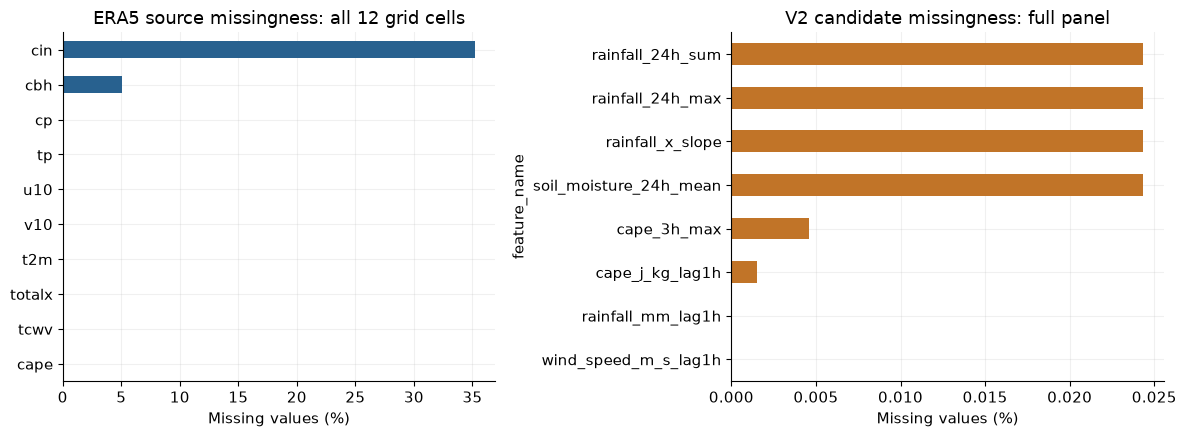

**Observed:** CAPE is complete at source; CIN is 35.19% missing
and cloud base is 5.04% missing. New leading nulls arise from strict warm-up
and the ERA5 source beginning at 08:00 Manila, not from failed geographic joins.
**Decision:** omit CIN/cloud base, retain null warm-up values, and expose `feature_complete` as metadata.
No imputer or scaler is fitted. Later preprocessing must be learned on eligible training data only.

In [5]:
new_missing = manifest.loc[manifest.feature_type.ne('source_only') & manifest.missing_pct.notna(),
    ['feature_name','missing_count','missing_pct','training_missing_pct']].sort_values('missing_pct',ascending=False)
display(new_missing.head(12).round(5))
old_quality = pd.read_csv(AUDIT/'legacy_feature_quality.csv')
display(old_quality.loc[old_quality.missing_pct.gt(0)].sort_values('missing_pct',ascending=False).head(10))
era_quality = pd.DataFrame(quality['era5']['variables']).T
era_quality['missing_pct'] = 100*era_quality['missing'].astype(float)/era_quality['values'].astype(float)
fig,axes = plt.subplots(1,2,figsize=(12,4.5))
era_quality.missing_pct.sort_values().plot.barh(ax=axes[0],color=BLUE)
axes[0].set(title='ERA5 source missingness: all 12 grid cells',xlabel='Missing values (%)')
top = new_missing.head(8).set_index('feature_name').missing_pct.sort_values()
top.plot.barh(ax=axes[1],color=ORANGE)
axes[1].set(title='V2 candidate missingness: full panel',xlabel='Missing values (%)')
finish('01_missingness')
display(Markdown(f"""**Observed:** CAPE is complete at source; CIN is {era_quality.loc['cin','missing_pct']:.2f}% missing
and cloud base is {era_quality.loc['cbh','missing_pct']:.2f}% missing. New leading nulls arise from strict warm-up
and the ERA5 source beginning at 08:00 Manila, not from failed geographic joins.
**Decision:** omit CIN/cloud base, retain null warm-up values, and expose `feature_complete` as metadata.
No imputer or scaler is fitted. Later preprocessing must be learned on eligible training data only."""))

In [6]:
missing_year = pd.read_csv(AUDIT/'missingness_by_year.csv')
missing_muni = pd.read_csv(AUDIT/'missingness_by_municipality.csv',dtype={'municipality_psgc':str})
display(missing_year.loc[missing_year.missing.gt(0)].sort_values('missing',ascending=False).head(8))
display(missing_muni.loc[missing_muni.missing.gt(0)].sort_values('missing',ascending=False).head(8))
display(Markdown(f"""**Coverage decision:** all {legacy['rows']:,} old-panel keys were scanned: zero gaps,
duplicate keys or invalid parent relationships. Municipal weather has {quality['weather']['rows']:,} rows and no nulls,
duplicate location-hours or gaps. Terrain matches every barangay. NDVI covers {len(ndvi):,} barangay-years,
but temporal publication validity remains unresolved, so completeness alone does not make it safe."""))

,year,feature,rows,missing,missing_pct
20,2019,rainfall_24h_sum,2074224,3792,0.182815
19,2019,rainfall_24h_max,2074224,3792,0.182815
24,2019,rainfall_x_slope,2074224,3792,0.182815
25,2019,soil_moisture_24h_mean,2074224,3792,0.182815
0,2019,cape_3h_max,2074224,711,0.034278
1,2019,cape_j_kg_lag1h,2074224,237,0.011426


,municipality_psgc,feature,rows,missing,missing_pct
133,0300804000,soil_moisture_24h_mean,3022384,736,0.024352
132,0300804000,rainfall_x_slope,3022384,736,0.024352
128,0300804000,rainfall_24h_sum,3022384,736,0.024352
127,0300804000,rainfall_24h_max,3022384,736,0.024352
312,0300809000,rainfall_x_slope,1905416,464,0.024352
313,0300809000,soil_moisture_24h_mean,1905416,464,0.024352
307,0300809000,rainfall_24h_max,1905416,464,0.024352
308,0300809000,rainfall_24h_sum,1905416,464,0.024352


**Coverage decision:** all 15,571,848 old-panel keys were scanned: zero gaps,
duplicate keys or invalid parent relationships. Municipal weather has 788,544 rows and no nulls,
duplicate location-hours or gaps. Terrain matches every barangay. NDVI covers 1,896 barangay-years,
but temporal publication validity remains unresolved, so completeness alone does not make it safe.

## 6. Synthetic outage EDA

**Question:** What did the simulator generate by cause, and how long do events last? **Method:** count all seven causes, show percentages, and inspect the complete duration distribution and cause-specific spread. Long right tails can be plausible in a simulator and are not a reason to delete observations. Animal Interference is a synthetic-only assumption. Scheduled PENELCO records are not occurrence labels.

,Events,Percent
Cause,,
Supply Interruption,2873,27.08
Tree Contact,2091,19.71
Unknown,1945,18.34
Other,1430,13.48
Equipment / Technical,1142,10.77
Weather / Storm,1012,9.54
Animal Interference,115,1.08


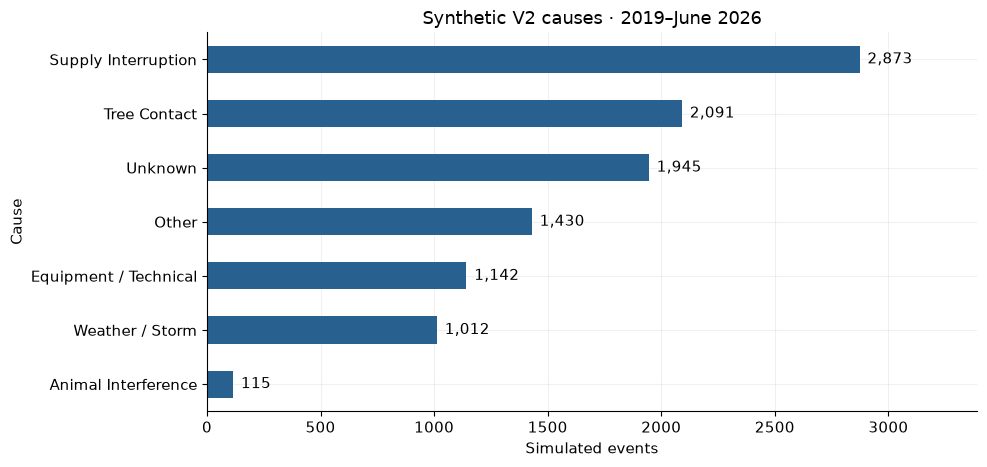

**Observed:** Supply Interruption is the largest category (2,873 events,
27.08%). Unknown and Other remain eligible unplanned events.
**Decision:** no cause filtering or cause-based predictor is introduced.

In [7]:
causes = events.cause_category.value_counts().rename_axis('Cause').to_frame('Events')
causes['Percent'] = 100*causes.Events/len(events)
display(causes.round(2))
ax = causes.Events.sort_values().plot.barh(color=BLUE,figsize=(10,4.8))
ax.set(title='Synthetic V2 causes · 2019–June 2026',xlabel='Simulated events')
for i,value in enumerate(causes.Events.sort_values()):
    ax.text(value+35,i,f'{value:,}',va='center')
ax.set_xlim(0,causes.Events.max()*1.18)
finish('02_causes')
display(Markdown(f"""**Observed:** {causes.index[0]} is the largest category ({causes.iloc[0].Events:,.0f} events,
{causes.iloc[0].Percent:.2f}%). Unknown and Other remain eligible unplanned events.
**Decision:** no cause filtering or cause-based predictor is introduced."""))

count    10608.00
mean        92.04
std        149.64
min          1.07
1%           3.62
50%         49.53
90%        198.84
95%        296.83
99%        685.30
max       2837.23
Name: Duration (minutes), dtype: float64

,count,mean,median,std,min,max
cause_category,,,,,,
Animal Interference,115,49.33,34.09,47.37,3.19,251.40
Equipment / Technical,1142,86.88,51.99,117.32,1.15,1618.45
Other,1430,62.71,41.90,69.91,1.51,1018.01
Supply Interruption,2873,111.79,58.75,175.70,1.66,2576.81
Tree Contact,2091,104.28,72.60,102.88,4.56,1124.67
Unknown,1945,41.63,27.61,47.57,1.40,541.70
Weather / Storm,1012,159.62,57.34,293.20,1.07,2837.23


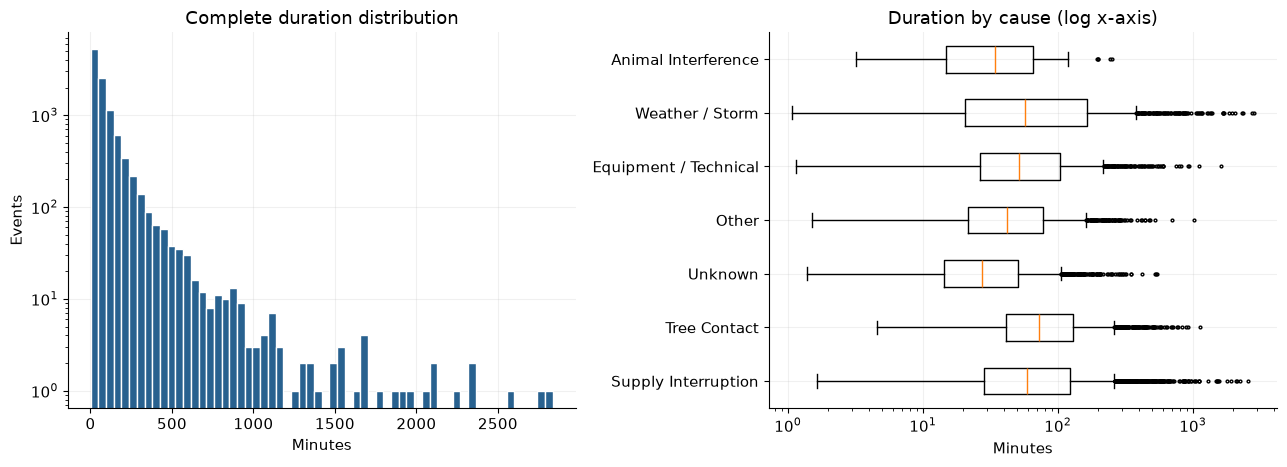

**Observed:** mean 92.04 min exceeds median 49.53 min;
P99 is 685.30 min and the maximum is 2837.23 min.
**Decision:** retain the full synthetic tail. Durations are used only for active-state eligibility and event EDA.

In [8]:
duration_stats = events.duration_minutes.describe(percentiles=[.01,.5,.9,.95,.99])
display(duration_stats.rename('Duration (minutes)').round(2))
cause_duration = events.groupby('cause_category').duration_minutes.agg(['count','mean','median','std','min','max'])
display(cause_duration.round(2))
fig,axes = plt.subplots(1,2,figsize=(13,4.8))
axes[0].hist(events.duration_minutes,bins=60,color=BLUE,edgecolor='white')
axes[0].set(title='Complete duration distribution',xlabel='Minutes',ylabel='Events',yscale='log')
order=causes.index.tolist()
axes[1].boxplot([events.loc[events.cause_category.eq(c),'duration_minutes'] for c in order],
    orientation='horizontal',tick_labels=order,showfliers=True,flierprops={'markersize':2})
axes[1].set(title='Duration by cause (log x-axis)',xlabel='Minutes',xscale='log')
finish('03_durations')
display(Markdown(f"""**Observed:** mean {duration_stats['mean']:.2f} min exceeds median {duration_stats['50%']:.2f} min;
P99 is {duration_stats['99%']:.2f} min and the maximum is {duration_stats['max']:.2f} min.
**Decision:** retain the full synthetic tail. Durations are used only for active-state eligibility and event EDA."""))

## 7. Spatial and temporal patterns

**Question:** Do time or geography dominate synthetic allocation? **Method:** compare event counts alongside the actual generation-exposure period. The 2026 period stops in June, so raw counts are never presented as a like-for-like annual trend. These event-EDA denominators are all potential generation hours, including active conditions; the onset model's eligible at-risk denominators appear in Sections 8 and 15.

Seasons are deliberately descriptive: **November–April = drier-month group**, **May–October = wetter-month group**. They are not event-specific monsoon classifications. Barangay assignments are probabilistic; apparent hotspots do not establish verified PENELCO reliability differences.

,Events,Exposure hours/barangay,Events / 10000 barangay-hours
start_time,,,
2019,1432,8752,6.9038
2020,1473,8784,7.0756
2021,1539,8760,7.4129
2022,1402,8760,6.7530
2023,1505,8760,7.2491
2024,1324,8784,6.3599
2025,1380,8760,6.6470
2026,553,4343,5.3726


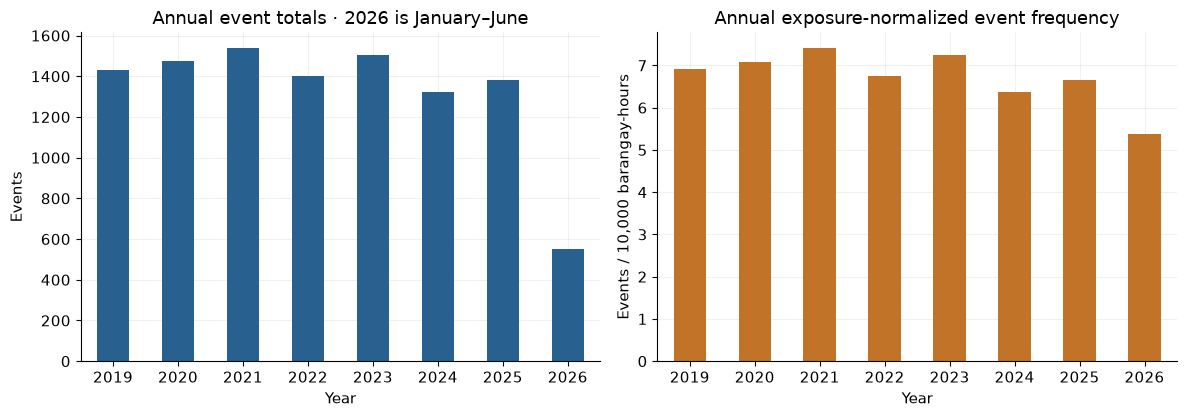

**Observed:** 2026 contains 553 events across
4,343 hours per barangay, compared with complete years earlier.
**Decision:** interpret the rate alongside the denominator. Neither curve measures actual utility performance.

In [9]:
coverage_start = pd.Timestamp(meta['date_coverage']['first_cutoff'])
coverage_end = pd.Timestamp(meta['date_coverage']['last_cutoff'])
generation_hours = pd.date_range(coverage_start,coverage_end,freq='h',inclusive='left')
annual = events.groupby(events.start_time.dt.year).size().rename('Events').to_frame()
annual['Exposure hours/barangay'] = pd.Series(generation_hours.year).value_counts().sort_index()
annual['Events / 10000 barangay-hours'] = 10000*annual.Events/(annual['Exposure hours/barangay']*len(geo))
display(annual.round(4))
fig,axes = plt.subplots(1,2,figsize=(12,4.3))
annual.Events.plot.bar(ax=axes[0],color=BLUE,rot=0)
axes[0].set(title='Annual event totals · 2026 is January–June',ylabel='Events',xlabel='Year')
annual['Events / 10000 barangay-hours'].plot.bar(ax=axes[1],color=ORANGE,rot=0)
axes[1].set(title='Annual exposure-normalized event frequency',ylabel='Events / 10,000 barangay-hours',xlabel='Year')
finish('04_annual')
display(Markdown(f"""**Observed:** 2026 contains {annual.loc[2026,'Events']:,} events across
{annual.loc[2026,'Exposure hours/barangay']:,} hours per barangay, compared with complete years earlier.
**Decision:** interpret the rate alongside the denominator. Neither curve measures actual utility performance."""))

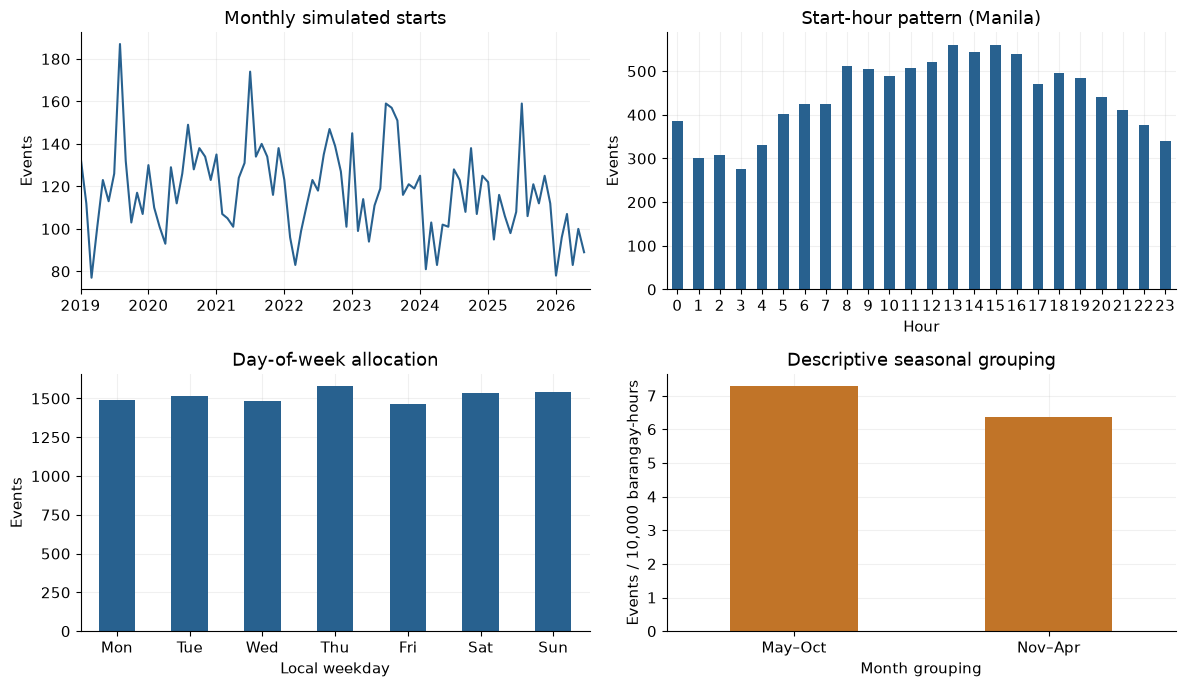

,events,barangay_hours,events_per_10000_hours
May–Oct,5582,7672875,7.275
Nov–Apr,5026,7898736,6.363


**Observed:** the largest monthly count is 187 in August 2019; the most frequently selected onset hour is 13:00 Manila. **Decision:** calendar structure is part of the simulation and environmental sampling. Retain cyclic hour/month encodings and a known weekend flag as research candidates; do not claim that generated cycles reproduce observed utility trends.

In [10]:
monthly = events.set_index('start_time').resample('MS').size()
fig,axes = plt.subplots(2,2,figsize=(12,7))
axes[0,0].plot(monthly.index,monthly.values,color=BLUE,lw=1.5)
axes[0,0].set(title='Monthly simulated starts',ylabel='Events')
axes[0,0].set_xlim(monthly.index.min(),coverage_end)
events.groupby(events.start_time.dt.hour).size().reindex(range(24),fill_value=0).plot.bar(ax=axes[0,1],color=BLUE,rot=0)
axes[0,1].set(title='Start-hour pattern (Manila)',xlabel='Hour',ylabel='Events')
events.groupby(events.start_time.dt.dayofweek).size().reindex(range(7),fill_value=0).set_axis(['Mon','Tue','Wed','Thu','Fri','Sat','Sun']).plot.bar(ax=axes[1,0],color=BLUE,rot=0)
axes[1,0].set(title='Day-of-week allocation',xlabel='Local weekday',ylabel='Events')
season = np.where(events.start_time.dt.month.isin([5,6,7,8,9,10]),'May–Oct','Nov–Apr')
season_hours=np.where(generation_hours.month.isin([5,6,7,8,9,10]),'May–Oct','Nov–Apr')
season_table = pd.Series(season).value_counts().rename('events').to_frame()
season_table['barangay_hours'] = pd.Series(season_hours).value_counts()*len(geo)
season_table['events_per_10000_hours']=10000*season_table.events/season_table.barangay_hours
season_table.events_per_10000_hours.plot.bar(ax=axes[1,1],color=ORANGE,rot=0)
axes[1,1].set(title='Descriptive seasonal grouping',ylabel='Events / 10,000 barangay-hours',xlabel='Month grouping')
finish('05_temporal')
display(season_table.round(4))
peak_hour=int(events.start_time.dt.hour.value_counts().idxmax())
display(Markdown(f'**Observed:** the largest monthly count is {monthly.max():,} in {monthly.idxmax():%B %Y}; the most frequently selected onset hour is {peak_hour:02d}:00 Manila. **Decision:** calendar structure is part of the simulation and environmental sampling. Retain cyclic hour/month encodings and a known weekend flag as research candidates; do not claim that generated cycles reproduce observed utility trends.'))

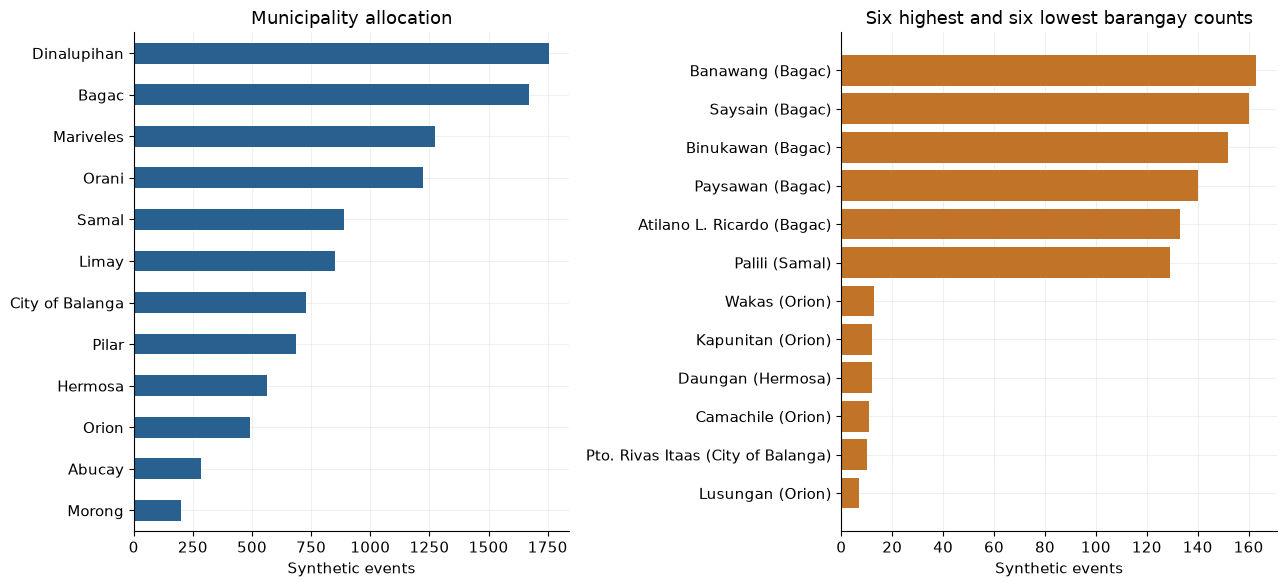

,barangay_psgc,barangay,municipality,events
10,0300802002,Banawang,Bagac,163
20,0300802014,Saysain,Bagac,160
12,0300802004,Binukawan,Bagac,152
17,0300802010,Paysawan,Bagac,140
22,0300802016,Atilano L. Ricardo,Bagac,133


,barangay_psgc,barangay,municipality,events
102,0300805009,Daungan,Hermosa,12
193,0300810016,Kapunitan,Orion,12
188,0300810010,Camachile,Orion,11
35,0300803015,Pto. Rivas Itaas,City of Balanga,10
195,0300810018,Lusungan,Orion,7


**Observed:** the top 10 selected barangays account for 12.84% of events;
count-concentration Gini is 0.336, and 0 barangays have no starts.
**Decision:** keep PSGCs as metadata; do not feed their numeric values to ML or call these verified outage hotspots.
Municipality shares are only partially PENELCO-calibrated; barangay allocations remain simulated.

In [11]:
municipal = events.groupby('municipality').size().reindex(geo.municipality.unique(),fill_value=0).sort_values()
barangay_counts = geo[['barangay_psgc','barangay','municipality']].merge(
    events.groupby('barangay_psgc').size().rename('events'),on='barangay_psgc',how='left',validate='one_to_one').fillna({'events':0})
barangay_counts['events']=barangay_counts.events.astype(int)
ranked=barangay_counts.sort_values(['events','barangay_psgc'],ascending=[False,True])
fig,axes=plt.subplots(1,2,figsize=(13,6))
municipal.plot.barh(ax=axes[0],color=BLUE)
axes[0].set(title='Municipality allocation',xlabel='Synthetic events',ylabel='')
selected=pd.concat([ranked.head(6),ranked.tail(6)]).sort_values('events')
axes[1].barh(selected.barangay+' ('+selected.municipality+')',selected.events,color=ORANGE)
axes[1].set(title='Six highest and six lowest barangay counts',xlabel='Synthetic events')
finish('06_geography')
display(ranked.head(5))
display(ranked.tail(5))
counts=np.sort(barangay_counts.events.to_numpy());n=len(counts)
gini=(2*np.sum(np.arange(1,n+1)*counts)/(n*counts.sum()))-(n+1)/n
top_share=100*ranked.head(10).events.sum()/len(events)
display(Markdown(f"""**Observed:** the top 10 selected barangays account for {top_share:.2f}% of events;
count-concentration Gini is {gini:.3f}, and {int(barangay_counts.events.eq(0).sum())} barangays have no starts.
**Decision:** keep PSGCs as metadata; do not feed their numeric values to ML or call these verified outage hotspots.
Municipality shares are only partially PENELCO-calibrated; barangay allocations remain simulated."""))

## 8. Environmental EDA

**Question:** How do event and eligible non-event conditions differ? **Why:** comparing only outages cannot establish a higher event rate. **Method:** inspect physical source distributions once per municipality-hour, then compare all eligible positive cutoffs with a deterministic sample of up to 600 negatives per month. Negative sampling weights recover each month's full negative exposure for distribution plots. Rates are calculated separately over **all** eligible rows, with exact denominators.

The municipal observations are shared by multiple barangays; ERA5 is shared across coarse grid cells. Copied weather values are not independent stations. The NDVI comparison below is explicitly **same-year retrospective context** and is not a predictor. No causal claim or statistical independence claim is made.

**Terminology:** CAPE means *convective available potential energy* (J/kg), a modeled atmospheric-instability indicator; higher CAPE alone does not establish a storm or an outage. NDVI means *normalized difference vegetation index*, a unitless spectral index from −1 to 1. Higher values often indicate greener vegetation, not measured power-line contact or tree-clearance distance.

,count,mean,50%,95%,99%,99.9%,max
precipitation_mm,788544.0,0.258,0.000,1.400,4.200,10.00,74.200
wind_speed_10m_m_s,788544.0,2.756,2.450,6.010,7.670,9.73,18.190
wind_gusts_10m_m_s,788544.0,6.637,6.200,13.200,16.600,21.20,35.000
soil_moisture_7_to_28cm_m3_m3,788544.0,0.333,0.325,0.506,0.517,0.52,0.522
soil_moisture_0_to_7cm_m3_m3,788544.0,0.341,0.346,0.507,0.517,0.52,0.528
temperature_2m_c,788544.0,27.283,26.800,32.000,34.300,36.10,39.000
relative_humidity_2m_pct,788544.0,80.616,83.000,97.000,99.000,100.00,100.000
surface_pressure_hpa,788544.0,1009.920,1009.900,1014.700,1016.900,1019.00,1021.700


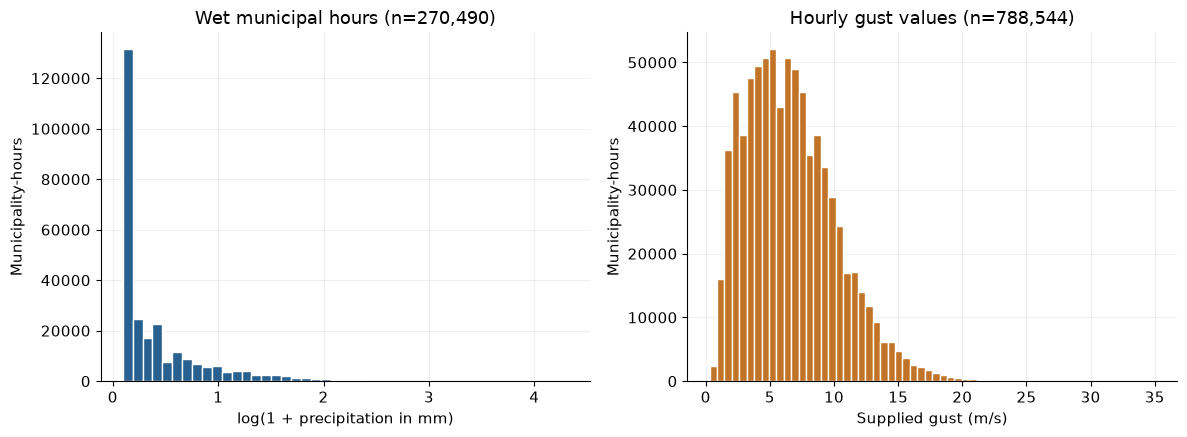

**Observed:** maximum source precipitation is 74.20 mm per hour
and gust is 35.00 m/s. These pass nonnegative/finite physical checks.
Humidity is bounded 0–100%, soil moisture 0–1 m³/m³, slope 0–90°. Statistical rarity alone cannot identify a source error.
**Decision:** preserve extremes; no winsorization or unexplained unit conversion is applied.

,municipality,time,precipitation_mm,wind_speed_10m_m_s,wind_gusts_10m_m_s
154986,City of Balanga,2021-09-08 18:00:00+08:00,74.2,6.63,23.6
680682,Pilar,2021-09-08 18:00:00+08:00,74.2,6.63,23.6
352122,Limay,2021-09-08 18:00:00+08:00,62.0,11.75,24.6
614970,Orion,2021-09-08 18:00:00+08:00,62.0,11.75,24.6
89276,Bagac,2021-09-08 20:00:00+08:00,61.4,4.83,34.7


,municipality,time,precipitation_mm,wind_speed_10m_m_s,wind_gusts_10m_m_s
1268,Abucay,2019-02-22 20:00:00+08:00,0.2,5.08,4.4
1844,Abucay,2019-03-18 20:00:00+08:00,0.0,4.06,3.8
1940,Abucay,2019-03-22 20:00:00+08:00,0.0,3.81,3.6
2492,Abucay,2019-04-14 20:00:00+08:00,0.0,2.31,2.2
2540,Abucay,2019-04-16 20:00:00+08:00,0.0,3.71,2.9


**Additional quality finding:** the 12 municipal series use only **7 distinct coordinate pairs**. There are **938 municipality-hours (0.1190%)** with supplied gust below supplied wind speed. The largest difference is -2.48 m/s. This unresolved measurement/interval consistency issue cannot be explained by rounding alone. Retain original values, report the issue, and verify source model/interval compatibility before deployment; do not invent a correction. High rain is clustered in concurrent municipal records and must not be counted as independent stations.

In [12]:
weather = pd.read_csv(source_path('weather'))
weather['time']=pd.to_datetime(weather.time).dt.tz_localize('Asia/Singapore').dt.tz_convert(TZ)
weather['municipality']=weather.municipality.replace({'Balanga':'City of Balanga'})
weather_summary = weather[list(RAW)].describe(percentiles=[.5,.95,.99,.999]).T
display(weather_summary[['count','mean','50%','95%','99%','99.9%','max']].round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
rain=weather.loc[weather.precipitation_mm.gt(0),'precipitation_mm']
axes[0].hist(np.log1p(rain),bins=45,color=BLUE,edgecolor='white')
axes[0].set(title=f'Wet municipal hours (n={len(rain):,})',xlabel='log(1 + precipitation in mm)',ylabel='Municipality-hours')
axes[1].hist(weather.wind_gusts_10m_m_s,bins=60,color=ORANGE,edgecolor='white')
axes[1].set(title=f'Hourly gust values (n={len(weather):,})',xlabel='Supplied gust (m/s)',ylabel='Municipality-hours')
finish('07_weather_distributions')
display(Markdown(f"""**Observed:** maximum source precipitation is {weather.precipitation_mm.max():.2f} mm per hour
and gust is {weather.wind_gusts_10m_m_s.max():.2f} m/s. These pass nonnegative/finite physical checks.
Humidity is bounded 0–100%, soil moisture 0–1 m³/m³, slope 0–90°. Statistical rarity alone cannot identify a source error.
**Decision:** preserve extremes; no winsorization or unexplained unit conversion is applied."""))
extreme_columns=['municipality','time','precipitation_mm','wind_speed_10m_m_s','wind_gusts_10m_m_s']
display(weather.nlargest(5,'precipitation_mm')[extreme_columns])
wind_discrepancy=weather.wind_gusts_10m_m_s.lt(weather.wind_speed_10m_m_s)
unique_coordinates=weather[['latitude','longitude']].drop_duplicates().shape[0]
display(weather.loc[wind_discrepancy,extreme_columns].head(5))
display(Markdown(f'**Additional quality finding:** the 12 municipal series use only **{unique_coordinates} distinct coordinate pairs**. There are **{wind_discrepancy.sum():,} municipality-hours ({100*wind_discrepancy.mean():.4f}%)** with supplied gust below supplied wind speed. The largest difference is {(weather.wind_gusts_10m_m_s-weather.wind_speed_10m_m_s).min():.2f} m/s. This unresolved measurement/interval consistency issue cannot be explained by rounding alone. Retain original values, report the issue, and verify source model/interval compatibility before deployment; do not invent a correction. High rain is clustered in concurrent municipal records and must not be counted as independent stations.'))

In [13]:
# Separate training-period spatial variation from variation over time.
training_weather=weather.loc[weather.time.lt(local('2024-01-01'))]
variability=[]
for feature in ['precipitation_mm','wind_gusts_10m_m_s','temperature_2m_c','soil_moisture_7_to_28cm_m3_m3']:
    grouped=training_weather.groupby('municipality')[feature]
    variability.append({'source feature':feature,'between-location SD of means':grouped.mean().std(),
        'mean within-location temporal SD':grouped.std().mean(),'spatial units':'12 municipal series; shared points'})
display(pd.DataFrame(variability).round(4))
display(terrain[['mean_slope_deg','mean_elevation_m','elevation_relief_p95_p05_m']].agg(['min','median','max','std']).round(3))
ndvi_coverage=ndvi.groupby(['year','period_type']).agg(barangays=('barangay_psgc','nunique'),
    mean_ndvi=('mean_ndvi','mean'),minimum_valid_coverage_pct=('valid_coverage_pct','min')).reset_index()
display(ndvi_coverage.round(4))
display(Markdown(f'**Observed and decision:** weather varies over time and across municipal representative points; terrain varies across {len(terrain)} barangays but is static over the panel. NDVI has annual observation windows rather than hourly freshness. The ERA5 assignment uses {quality["era5"]["assigned_cells"]} coarse cells. Preserve these grains when interpreting associations; repeated hourly copies do not create new measurement locations.'))

,source feature,between-location SD of means,mean within-location temporal SD,spatial units
0,precipitation_mm,0.0349,0.9329,12 municipal series; shared points
1,wind_gusts_10m_m_s,1.0099,3.3893,12 municipal series; shared points
2,temperature_2m_c,0.3036,2.3589,12 municipal series; shared points
3,soil_moisture_7_to_28cm_m3_m3,0.0543,0.1001,12 municipal series; shared points


,mean_slope_deg,mean_elevation_m,elevation_relief_p95_p05_m
min,0.440,0.400,0.900
median,2.090,11.600,14.600
max,19.820,572.900,1078.900
std,5.037,107.584,213.076


,year,period_type,barangays,mean_ndvi,minimum_valid_coverage_pct
0,2019,full_year,237,0.4640,100.0
1,2020,full_year,237,0.4892,100.0
2,2021,full_year,237,0.4752,100.0
3,2022,full_year,237,0.4766,100.0
4,2023,full_year,237,0.4906,100.0
5,2024,full_year,237,0.4511,100.0
6,2025,full_year,237,0.4671,100.0
7,2026,year_to_date,237,0.4459,100.0


**Observed and decision:** weather varies over time and across municipal representative points; terrain varies across 237 barangays but is static over the panel. NDVI has annual observation windows rather than hourly freshness. The ERA5 assignment uses 4 coarse cells. Preserve these grains when interpreting associations; repeated hourly copies do not create new measurement locations.

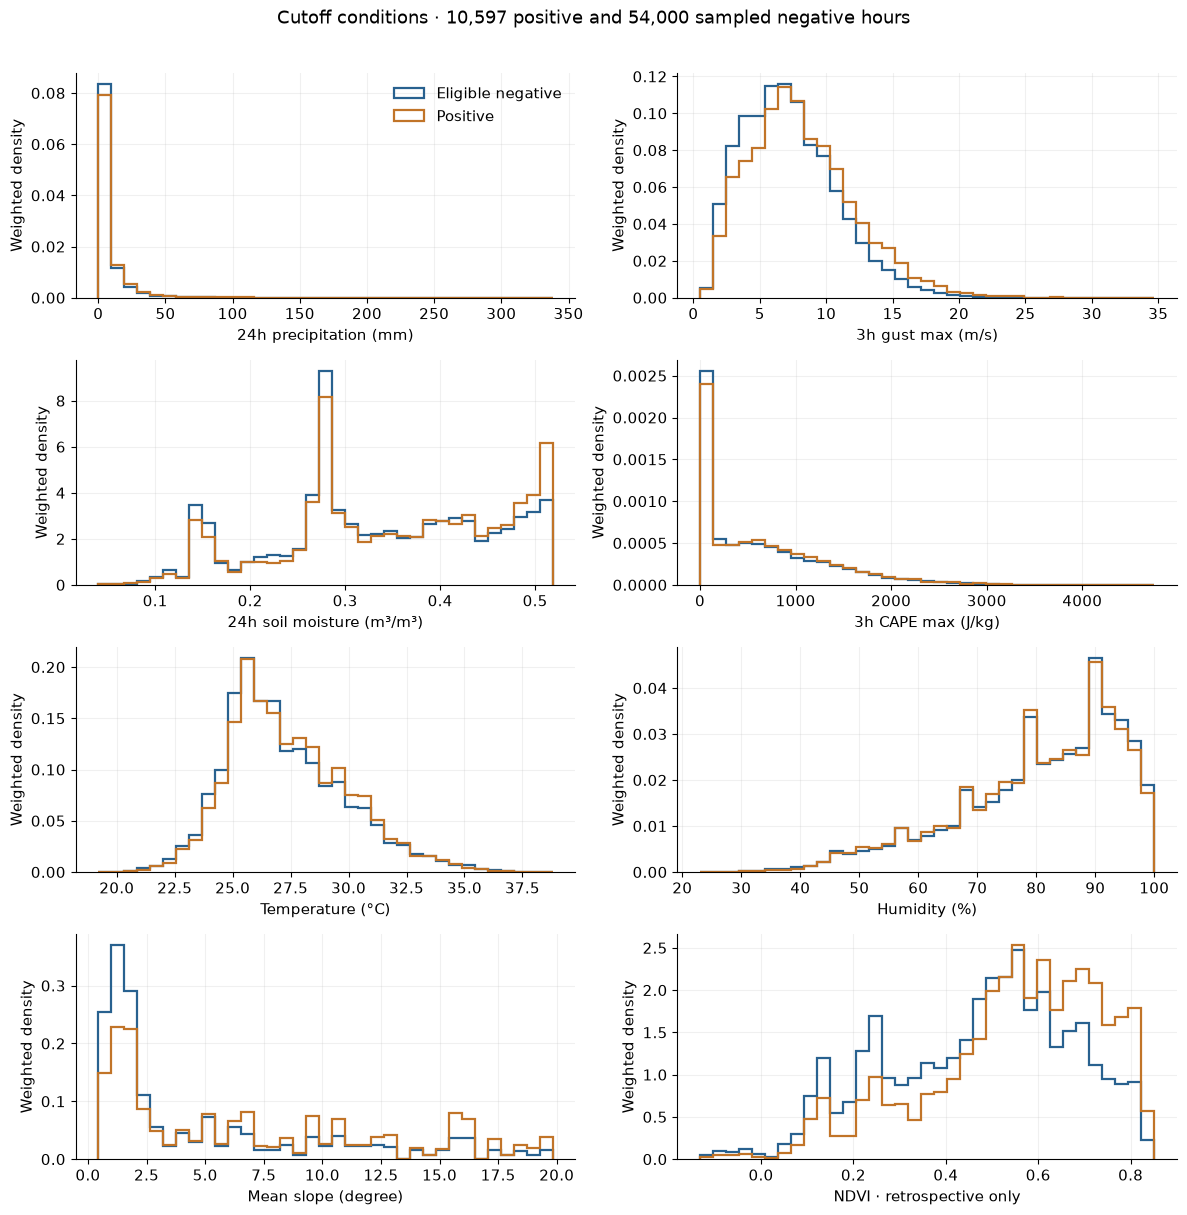

,condition (units),positive mean,negative weighted-sample mean
0,24h precipitation (mm),7.884,6.082
1,3h gust max (m/s),8.180,7.263
2,24h soil moisture (m³/m³),0.350,0.334
3,3h CAPE max (J/kg),648.394,619.082
4,Temperature (°C),27.421,27.220
5,Humidity (%),80.251,80.525
6,Mean slope (degree),6.934,4.803
7,NDVI · retrospective only,0.549,0.473


**Interpretation and decision:** curves describe simulated associations at the prediction cutoff. Monthly negative weights correct the sample design; they are for EDA only and never rebalance the canonical dataset. Same-year NDVI can reveal how the generator used vegetation, but its future imagery disqualifies it from the ML matrix.

In [14]:
comparison=pd.read_parquet(AUDIT/'eda_comparison_sample.parquet')
positive=comparison.outage_next_hour.eq(1);negative=comparison.outage_next_hour.eq(0)
dimensions=[('rainfall_24h_sum','24h precipitation (mm)'),('wind_gust_3h_max','3h gust max (m/s)'),
    ('soil_moisture_24h_mean','24h soil moisture (m³/m³)'),('cape_3h_max','3h CAPE max (J/kg)'),
    ('temperature_c_lag1h','Temperature (°C)'),('humidity_pct_lag1h','Humidity (%)'),
    ('mean_slope_deg','Mean slope (degree)'),('ndvi_same_year_context','NDVI · retrospective only')]
fig,axes=plt.subplots(4,2,figsize=(12,12))
for ax,(feature,label) in zip(axes.flat,dimensions):
    vals=comparison[feature].dropna();bins=np.histogram_bin_edges(vals,bins=35)
    for mask,name,color in [(negative,'Eligible negative',BLUE),(positive,'Positive',ORANGE)]:
        valid=mask & comparison[feature].notna()
        ax.hist(comparison.loc[valid,feature],bins=bins,weights=comparison.loc[valid,'comparison_weight'],
            density=True,histtype='step',linewidth=1.6,color=color,label=name)
    ax.set(xlabel=label,ylabel='Weighted density')
axes[0,0].legend(frameon=False)
fig.suptitle(f'Cutoff conditions · {positive.sum():,} positive and {negative.sum():,} sampled negative hours',y=1.01)
finish('08_positive_negative')
condition_means=[]
for feature,label in dimensions:
    values=[]
    for mask in [positive,negative]:
        valid=mask & comparison[feature].notna()
        values.append(np.average(comparison.loc[valid,feature],weights=comparison.loc[valid,'comparison_weight']))
    condition_means.append({'condition (units)':label,'positive mean':values[0],
        'negative weighted-sample mean':values[1]})
display(pd.DataFrame(condition_means).round(3))
display(Markdown('**Interpretation and decision:** curves describe simulated associations at the prediction cutoff. Monthly negative weights correct the sample design; they are for EDA only and never rebalance the canonical dataset. Same-year NDVI can reveal how the generator used vegetation, but its future imagery disqualifies it from the ML matrix.'))

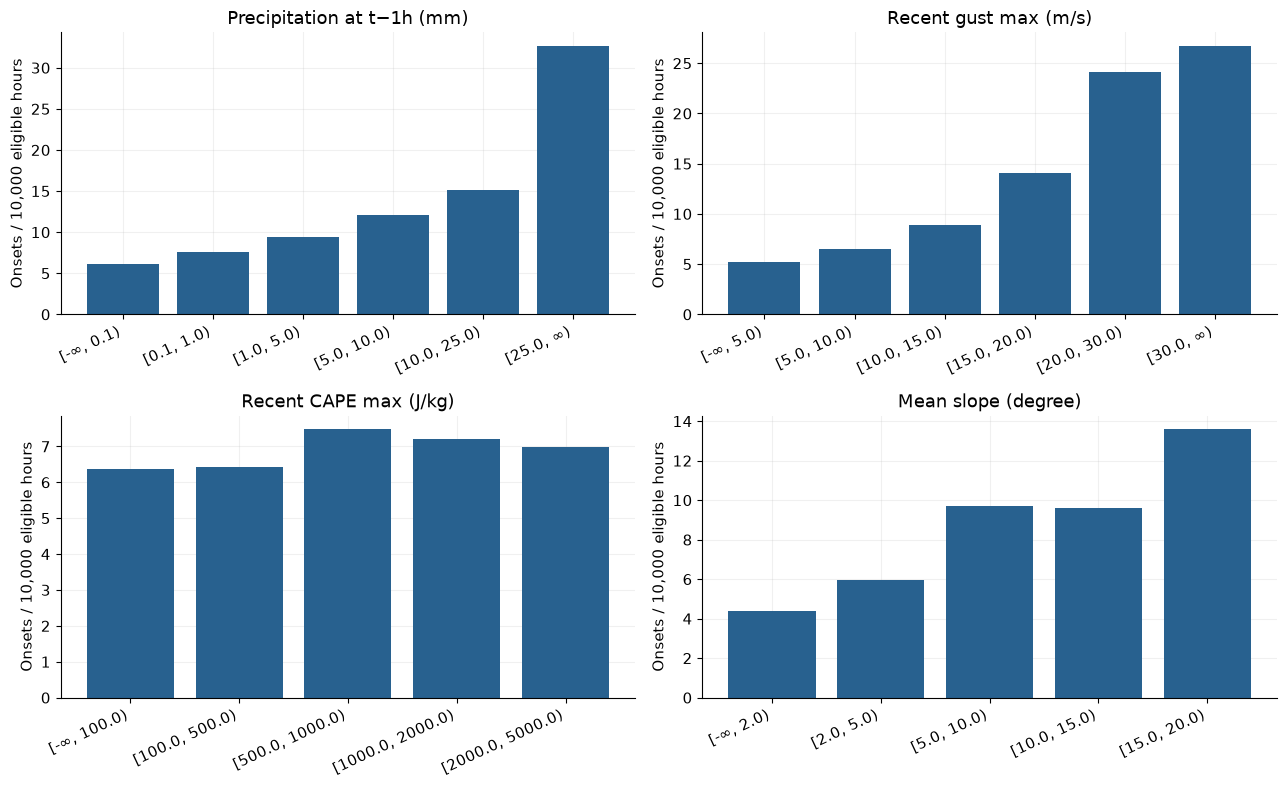

,bin,eligible_hours,positives,onsets_per_10000_hours
45,"[-inf, 5.0)",4397682,2306,5.2437
46,"[10.0, 15.0)",2783757,2473,8.8837
47,"[15.0, 20.0)",383559,541,14.1047
48,"[20.0, 30.0)",31911,77,24.1296
49,"[30.0, inf)",748,2,26.7380
50,"[5.0, 10.0)",7951493,5198,6.5371


**Observed:** the highest gust-bin simulated onset rate is 26.738 per 10,000 eligible hours in [30.0, inf) m/s, from 2 positives / 748 eligible hours. **Decision:** use full-population denominators for rates and make no causal or real utility forecasting claim. Bins are prespecified physical ranges, not optimized on final test labels. NDVI rates are descriptive post hoc context only.

In [15]:
rates=pd.read_csv(AUDIT/'environmental_rates.csv')
fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,feature,label in zip(axes.flat,
    ['rainfall_mm_lag1h','wind_gust_3h_max','cape_3h_max','mean_slope_deg'],
    ['Precipitation at t−1h (mm)','Recent gust max (m/s)','Recent CAPE max (J/kg)','Mean slope (degree)']):
    r=rates.loc[rates.feature.eq(feature)].copy()
    def low_bound(text):return float(text.split(',')[0].replace('[','').replace('(',''))
    r=r.sort_values('bin',key=lambda x:x.map(low_bound))
    ax.bar(np.arange(len(r)),r.onsets_per_10000_hours,color=BLUE)
    ax.set_xticks(np.arange(len(r)),[x.replace('inf','∞') for x in r.bin],rotation=25,ha='right')
    ax.set(title=label,ylabel='Onsets / 10,000 eligible hours')
finish('09_environment_rates')
display(rates.loc[rates.feature.eq('wind_gust_3h_max'),['bin','eligible_hours','positives','onsets_per_10000_hours']].round(4))
gust_rates=rates.loc[rates.feature.eq('wind_gust_3h_max')]
highest=gust_rates.loc[gust_rates.onsets_per_10000_hours.idxmax()]
display(Markdown(f'**Observed:** the highest gust-bin simulated onset rate is {highest.onsets_per_10000_hours:.3f} per 10,000 eligible hours in {highest["bin"]} m/s, from {highest.positives:,} positives / {highest.eligible_hours:,} eligible hours. **Decision:** use full-population denominators for rates and make no causal or real utility forecasting claim. Bins are prespecified physical ranges, not optimized on final test labels. NDVI rates are descriptive post hoc context only.'))

## 9. Feature correlation and redundancy

**Question:** Are we exporting multiple names for almost the same information? **Method:** calculate Spearman correlation (rank similarity), unique values and modal proportions on an eligible training-only sample (1,500 rows/month). Exact missingness is measured on the full training population. Static terrain is repeated over time, so these correlations describe this panel population, not independent terrain measurements.

No target correlation, validation metric, final-test optimization or model fitting selects features. Thresholds within the rain/wind families remove redundant middle windows; the 3h and 24h contexts remain interpretable hypotheses. Near-constant precipitation at zero is physically meaningful and is not automatically deleted.

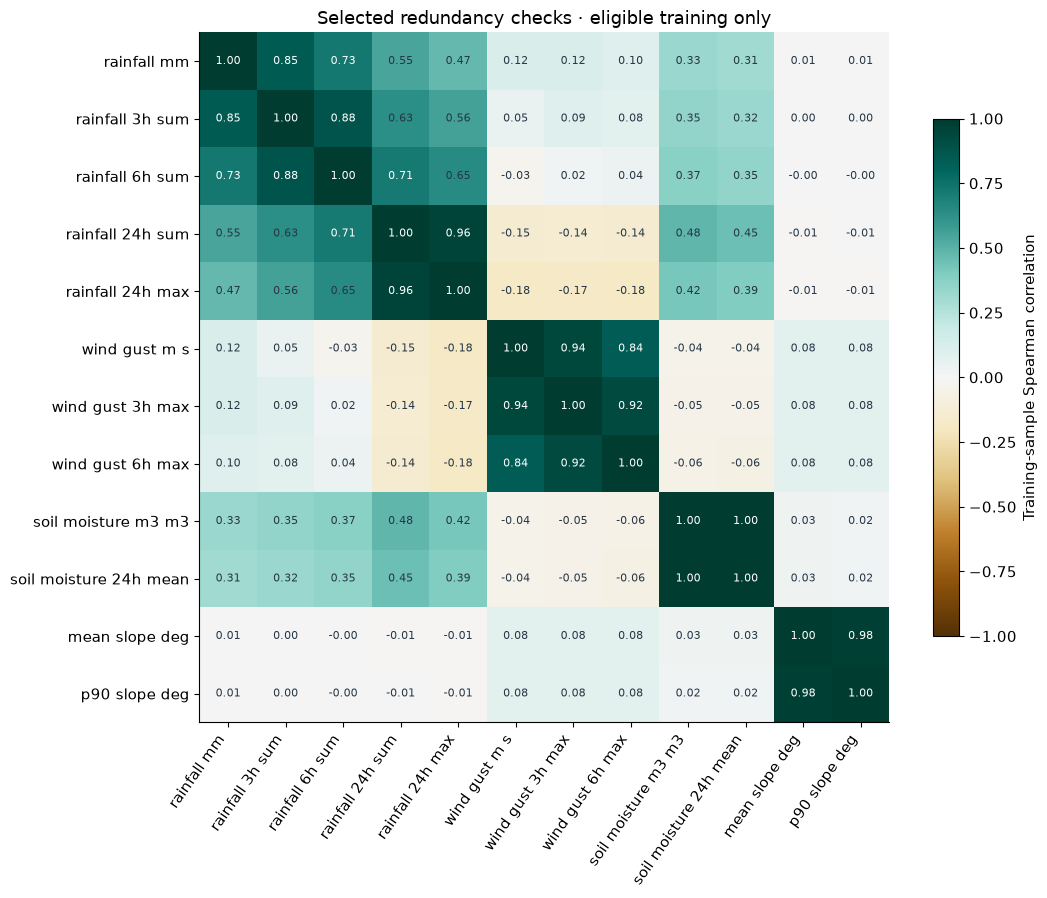

,feature,sample_unique_values,sample_mode_pct,training_missing_pct
23,consecutive_rainy_hours,73,76.7500,0.0000
35,is_weekend,2,71.3311,0.0000
0,rainfall_mm_lag1h,145,64.6511,0.0000
18,pct_area_slope_gt_15_deg,102,55.8378,0.0000
19,rainfall_3h_sum,282,52.0756,0.0000
20,rainfall_6h_sum,436,40.4400,0.0000
34,month_cos,8,16.6667,0.0000
33,month_sin,8,16.6667,0.0000
8,cape_j_kg_lag1h,14423,13.6668,0.0023
22,rainfall_24h_max,200,13.6235,0.0365


,feature_name,selection_reason
3,soil_moisture_m3_m3_lag1h,Training-sample |Spearman rho|=0.9951 >= 0.95 ...
8,cape_j_kg_lag1h,Use the recent 3h maximum for the initial inst...
12,p90_slope_deg,Redundant terrain summaries; retain mean slope...
13,median_elevation_m,Redundant terrain summaries; retain mean slope...
14,median_slope_deg,Redundant terrain summaries; retain mean slope...
15,elevation_p05_m,Redundant terrain summaries; retain mean slope...
16,elevation_p95_m,Redundant terrain summaries; retain mean slope...
17,elevation_std_m,Redundant terrain summaries; retain mean slope...
18,pct_area_slope_gt_15_deg,Redundant terrain summaries; retain mean slope...
25,wind_gust_6h_max,Training-sample |Spearman rho|=0.9234 >= 0.9 w...


**Decision:** keep distinct physical summaries and cyclic encodings, drop documented redundancy, and defer unsupported availability. These unsupervised choices freeze an initial research matrix; later train/validation ablation may establish whether candidates add predictive value.

In [16]:
corr=pd.read_csv(AUDIT/'training_spearman_correlations.csv',index_col='feature')
train_quality=pd.read_csv(AUDIT/'training_feature_quality.csv')
selected=['rainfall_mm_lag1h','rainfall_3h_sum','rainfall_6h_sum','rainfall_24h_sum',
    'rainfall_24h_max','wind_gust_m_s_lag1h','wind_gust_3h_max','wind_gust_6h_max',
    'soil_moisture_m3_m3_lag1h','soil_moisture_24h_mean','mean_slope_deg','p90_slope_deg']
fig,ax=plt.subplots(figsize=(11,9))
image=ax.imshow(corr.loc[selected,selected],vmin=-1,vmax=1,cmap='BrBG')
labels=[x.replace('_lag1h','').replace('_',' ') for x in selected]
ax.set_xticks(range(len(selected)),labels,rotation=55,ha='right')
ax.set_yticks(range(len(selected)),labels)
ax.grid(False)
for i in range(len(selected)):
    for j in range(len(selected)):
        value=corr.loc[selected[i],selected[j]]
        ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=8,color='white' if abs(value)>.65 else CHARCOAL)
fig.colorbar(image,ax=ax,label='Training-sample Spearman correlation',shrink=.75)
ax.set_title('Selected redundancy checks · eligible training only')
finish('10_correlations')
display(train_quality[['feature','sample_unique_values','sample_mode_pct','training_missing_pct']].sort_values('sample_mode_pct',ascending=False).head(10).round(4))
display(manifest.loc[manifest.status.eq('dropped') & manifest.feature_type.ne('source_only'),['feature_name','selection_reason']])
display(Markdown('**Decision:** keep distinct physical summaries and cyclic encodings, drop documented redundancy, and defer unsupported availability. These unsupervised choices freeze an initial research matrix; later train/validation ablation may establish whether candidates add predictive value.'))

## 10. Feature engineering

**Question:** Can recent weather history provide more context than one observation? A single dry hour may follow a day of rain; one wind value may miss a recent peak. We therefore summarize trailing, complete histories **within each source location before copying values to barangays**.

With a one-hour lag, a $W$-hour sum at cutoff $t$ uses source labels $t-W,\ldots,t-1$. For precipitation, whose label is the end of the preceding hour, the physical interval is $(t-W-1,t-1]$:

$$R_W(t)=\sum_{j=1}^{W}p(t-j\mathrm{h}).$$

Means and maxima use the same label bounds. Gust change is $g(t-1)-g(t-4)$; rainy streak counts consecutive values **strictly above 0.1 mm**, capped at 72h. An unknown wet left edge stays null until a dry hour or cap establishes its value. No centered window, future value, backward fill, interpolation or partial-window aggregate is allowed.

The rainfall–slope candidate is `rainfall_24h_sum × mean_slope_deg` (mm·degree). It is an interpretable empirical interaction hypothesis, not a dimensional physical failure law. A wind–NDVI candidate cannot be made temporally valid from the available NDVI publication metadata and is deferred. The EDA-only retrospective illustration is explicitly named differently.

In [17]:
municipality=weather.municipality.iloc[0]
raw=weather.loc[weather.municipality.eq(municipality)].set_index('time').sort_index()
demo=engineer_weather(raw,
    rain_threshold=meta['transformations']['rain_threshold_mm_strict_greater'],
    streak_cap=meta['transformations']['rain_streak_cap_hours'])
t=raw.index[30]
hand_sum=raw.loc[t-pd.Timedelta(hours=24):t-HOUR,'precipitation_mm'].sum()
assert np.isclose(demo.loc[t,'rainfall_24h_sum'],hand_sum)
future_changed=raw.copy();future_changed.loc[t:,list(RAW)]=9999
pd.testing.assert_frame_equal(demo.loc[:t],engineer_weather(future_changed).loc[:t])
display(demo.loc[t-pd.Timedelta(hours=2):t+pd.Timedelta(hours=2),
    ['rainfall_mm_lag1h','rainfall_3h_sum','rainfall_6h_sum','rainfall_24h_sum','wind_gust_3h_max']].round(3))
display(Markdown(f'**Observed:** at {t}, hand-summed prior-24-hour precipitation is **{hand_sum:.3f} mm**, matching the shared builder definition. Changing source values at/after the cutoff leaves all earlier feature values unchanged. **Decision:** reuse this exact function in the notebook and builder.'))

,rainfall_mm_lag1h,rainfall_3h_sum,rainfall_6h_sum,rainfall_24h_sum,wind_gust_3h_max
2019-01-02 04:00:00+08:00,0.0,0.0,0.0,4.9,9.3
2019-01-02 05:00:00+08:00,0.0,0.0,0.0,4.9,9.3
2019-01-02 06:00:00+08:00,0.0,0.0,0.0,4.9,9.3
2019-01-02 07:00:00+08:00,0.0,0.0,0.0,4.9,9.0
2019-01-02 08:00:00+08:00,0.0,0.0,0.0,4.9,8.5


**Observed:** at 2019-01-02 06:00:00+08:00, hand-summed prior-24-hour precipitation is **4.900 mm**, matching the shared builder definition. Changing source values at/after the cutoff leaves all earlier feature values unchanged. **Decision:** reuse this exact function in the notebook and builder.

### Calendar features and units

23:00 and 00:00 are neighbors in time. Encoding hour as an ordinary number would place them far apart. Sine/cosine represent position around a circle:

$$h_{\sin}=\sin(2\pi h/24),\quad h_{\cos}=\cos(2\pi h/24).$$

Month uses $(m-1)/12$, so December and January are adjacent. `is_weekend` is known from the cutoff clock. All five are known in advance and need no fitted transformation. Raw PSGCs are identifiers and do not have a meaningful continuous numerical distance.

In [18]:
display(manifest.loc[manifest.feature_type.eq('engineered'),['feature_name','unit','status','calculation']])
wrap_times=pd.DatetimeIndex([local('2023-12-31 23:00'),local('2024-01-01 00:00')])
display(calendar_features(wrap_times).round(4))
display(Markdown(f'**Decision:** {meta["engineered_created"]} valid-time-causal engineered candidates are computed; {meta["engineered_retained"]} enter the initial matrix. Wind × NDVI remains deferred; no vegetation value or release date is fabricated.'))

,feature_name,unit,status,calculation
19,rainfall_3h_sum,mm,kept,Trailing 3 complete hourly labels t-3h ... t-1...
20,rainfall_6h_sum,mm,kept,Trailing 6 complete hourly labels t-6h ... t-1...
21,rainfall_24h_sum,mm,kept,Trailing 24 complete hourly labels t-24h ... t...
22,rainfall_24h_max,mm,kept,Trailing 24 complete hourly labels t-24h ... t...
23,consecutive_rainy_hours,hours,kept,Consecutive >0.1 mm hours ending t-1h; capped ...
24,wind_gust_3h_max,m/s,kept,Trailing 3 complete hourly labels t-3h ... t-1...
25,wind_gust_6h_max,m/s,dropped,Trailing 6 complete hourly labels t-6h ... t-1...
26,wind_speed_3h_mean,m/s,kept,Trailing 3 complete hourly labels t-3h ... t-1...
27,wind_gust_change_3h,m/s,kept,gust(t-1h) - gust(t-4h)
28,soil_moisture_24h_mean,m3/m3,kept,Trailing 24 complete hourly labels t-24h ... t...


,hour_sin,hour_cos,month_sin,month_cos,is_weekend
2023-12-31 23:00:00+08:00,-0.2588,0.9659,-0.5,0.866,1.0
2024-01-01 00:00:00+08:00,0.0000,1.0000,0.0,1.000,0.0


**Decision:** 17 valid-time-causal engineered candidates are computed; 16 enter the initial matrix. Wind × NDVI remains deferred; no vegetation value or release date is fabricated.

## 11. Before-and-after feature comparisons

**Question:** What does a rolling feature add to a raw hourly measurement? **Method:** select an actual eligible positive cutoff from the audit sample and show the recent source history. The first panel is lagged hourly precipitation; the second is its complete trailing 24h accumulation. They have different interpretations and are not interchangeable. Lines beyond the highlighted cutoff are descriptive context, not inputs to that prediction.

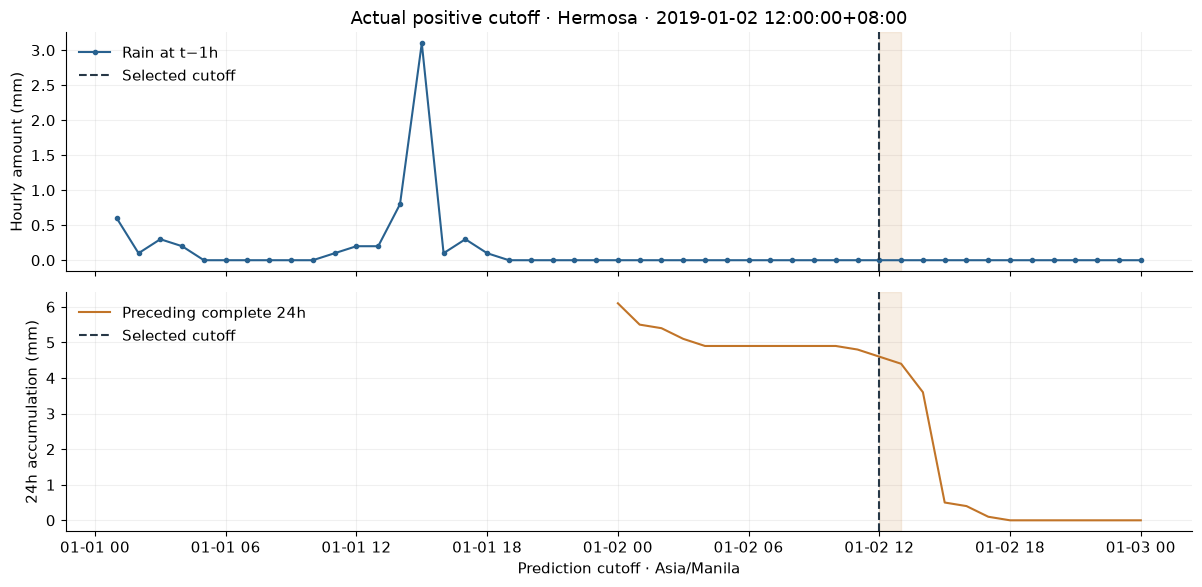

,Actual value
prediction_time,2019-01-02 12:00:00+08:00
barangay_psgc,0300805002
rainfall_mm_lag1h,0.0
rainfall_24h_sum,4.6
wind_gust_3h_max,12.6
mean_slope_deg,1.21
rainfall_x_slope,5.566


**Decision:** retain prior-history context where it adds a distinct interpretable summary; remove the redundant middle window when training-period rank correlation crosses the specified threshold. Shaded time is the future label window, never realized-weather input.

In [19]:
example=comparison.loc[comparison.outage_next_hour.eq(1) & comparison.rainfall_24h_sum.gt(0)].iloc[0]
cutoff=example.prediction_time
municipal_name=geo.set_index('municipality_psgc').loc[example.municipality_psgc,'municipality']
if isinstance(municipal_name,pd.Series):municipal_name=municipal_name.iloc[0]
source=weather.loc[weather.municipality.eq(municipal_name)].set_index('time').sort_index()
engineered=engineer_weather(source)
window=engineered.loc[cutoff-pd.Timedelta(hours=36):cutoff+pd.Timedelta(hours=12)]
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
axes[0].plot(window.index,window.rainfall_mm_lag1h,color=BLUE,marker='.',label='Rain at t−1h')
axes[0].set(ylabel='Hourly amount (mm)',title=f'Actual positive cutoff · {municipal_name} · {cutoff}')
axes[1].plot(window.index,window.rainfall_24h_sum,color=ORANGE,label='Preceding complete 24h')
axes[1].set(ylabel='24h accumulation (mm)',xlabel='Prediction cutoff · Asia/Manila')
for ax in axes:
    ax.axvline(cutoff,color=CHARCOAL,linestyle='--',label='Selected cutoff')
    ax.axvspan(cutoff,cutoff+HOUR,color=ORANGE,alpha=.12)
    ax.legend(frameon=False,loc='upper left')
finish('11_before_after')
display(example[['prediction_time','barangay_psgc','rainfall_mm_lag1h','rainfall_24h_sum','wind_gust_3h_max','mean_slope_deg','rainfall_x_slope']].to_frame('Actual value'))
display(Markdown('**Decision:** retain prior-history context where it adds a distinct interpretable summary; remove the redundant middle window when training-period rank correlation crosses the specified threshold. Shaded time is the future label window, never realized-weather input.'))

## 12. Feature selection and excluded columns

**Question:** Which fields are actually supplied to a future estimator? **Method:** use an explicit predictor whitelist, separate from metadata, target, eligibility flags and analytical outcomes. The next table shows the final physical/calendar subset. The CSV manifest records **every** candidate and source-only exclusion with status, reason, source, units, calculation, availability and missingness.

The initial matrix excludes outage IDs, cause, duration, restoration/end time, severity, generator scores/probabilities/seeds/versions, fault asset assignments, affected assets/barangays and downstream impact statistics. Uncertain static infrastructure densities are deferred. These fields are preserved in their original sources. Geographic categoricals would need a separately justified experiment addressing fixed synthetic geographic memorization.

In [20]:
display(manifest.loc[manifest.retained,['feature_name','feature_type','unit','missing_pct']].round(6))
display(manifest.loc[manifest.status.eq('deferred') & manifest.feature_type.ne('source_only'),
    ['feature_name','selection_reason']])
assert predictors == manifest.loc[manifest.retained,'feature_name'].tolist()
assert not set(predictors).intersection(meta['metadata_columns']+['outage_next_hour'])
display(Markdown(f'**Decision:** freeze **{len(predictors)}** predictors; **{int((~manifest.retained).sum())}** registered candidate/source fields are not retained. See `ml_feature_manifest.csv` for the full explicit exclusion list. Feature selection does not inspect test labels or train a model.'))

,feature_name,feature_type,unit,missing_pct
0,rainfall_mm_lag1h,original,mm,0.000000
1,wind_speed_m_s_lag1h,original,m/s,0.000000
2,wind_gust_m_s_lag1h,original,m/s,0.000000
5,temperature_c_lag1h,original,deg C,0.000000
6,humidity_pct_lag1h,original,%,0.000000
9,mean_slope_deg,original,degree,0.000000
10,elevation_relief_p95_p05_m,original,m,0.000000
11,mean_elevation_m,original,m,0.000000
19,rainfall_3h_sum,engineered,mm,0.000000
20,rainfall_6h_sum,engineered,mm,0.000000


,feature_name,selection_reason
4,soil_moisture_shallow_m3_m3_lag1h,Additional source measurement; initial subset ...
7,surface_pressure_hpa_lag1h,Additional source measurement; initial subset ...
36,ndvi,Cannot create a prediction-time-valid NDVI inp...
37,wind_gust_x_ndvi,Cannot create a prediction-time-valid NDVI inp...


**Decision:** freeze **24** predictors; **143** registered candidate/source fields are not retained. See `ml_feature_manifest.csv` for the full explicit exclusion list. Feature selection does not inspect test labels or train a model.

## 13. Label construction and validation

**Question:** Do event starts reconcile with binary positive hours and all exclusion rules? **Method:** the builder groups only synthetic **origin barangays** into the right-closed next-hour window, then applies active, coverage and split masks. Multiple eligible starts in one window yield one binary positive. A separate validator reads every exported partition and recomputes every label by sorted timestamp searches, independently of the builder's label helper.

This small example shows an actual event's origin before, during and after onset. An event at the cutoff is active; it does not count as a future start. A restored barangay re-enters the onset population at its exact restoration boundary.

In [21]:
actual_event=events.loc[events.barangay_psgc.eq(example.barangay_psgc) & events.start_time.eq(cutoff+HOUR)].iloc[0]
clock=pd.date_range(cutoff-HOUR,actual_event.end_time.ceil('h')+HOUR,freq='h')
origin_events=events.loc[events.barangay_psgc.eq(actual_event.barangay_psgc)]
counts,active,eligible,reasons=label_arrays(origin_events,clock,[actual_event.barangay_psgc],
    coverage_start,coverage_end,local('2024-01-01'),local('2025-01-01'))
demo_labels=pd.DataFrame({'cutoff':clock,'starts_in_(t,t+1h]':counts[:,0],
    'active_at_cutoff':active[:,0],'is_eligible':eligible[:,0],'reason':reasons[:,0]})
demo_labels['target']=pd.array((counts[:,0]>0).astype('uint8'),dtype='UInt8')
demo_labels.loc[~demo_labels.is_eligible,'target']=pd.NA
display(demo_labels.head(12))
display(pd.DataFrame([{'independent check':k,'result':v} for k,v in validation.items() if isinstance(v,(str,int,bool))]))
display(Markdown(f'**Verified result:** {meta["positive_rows"]:,} positive hours remain after explicit boundary/mask reconciliation. Unknown/Other causes remain eligible; topology impact relationships never generate positives. No V1 occurrence labels enter the output.'))

,cutoff,"starts_in_(t,t+1h]",active_at_cutoff,is_eligible,reason,target
0,2019-01-02 11:00:00+08:00,0,False,True,eligible,0
1,2019-01-02 12:00:00+08:00,1,False,True,eligible,1
2,2019-01-02 13:00:00+08:00,0,True,False,active_outage,<NA>
3,2019-01-02 14:00:00+08:00,0,True,False,active_outage,<NA>
4,2019-01-02 15:00:00+08:00,0,True,False,active_outage,<NA>
5,2019-01-02 16:00:00+08:00,0,False,True,eligible,0
6,2019-01-02 17:00:00+08:00,0,False,True,eligible,0


,independent check,result
0,status,passed
1,independent_full_export_scan,True
2,rows,15571848
3,positives,10597
4,negatives,15538553
5,excluded,22698
6,eligible,15549150
7,feature_values_checked,373724352
8,partitions,90
9,columns,32


**Verified result:** 10,597 positive hours remain after explicit boundary/mask reconciliation. Unknown/Other causes remain eligible; topology impact relationships never generate positives. No V1 occurrence labels enter the output.

## 14. Final dataset structure

**Question:** Can another researcher load the table safely? **Method:** inspect a monthly file's Arrow schema and a compact CSV preview. Partition folders encode calendar year/month; they do not create additional model predictors. `outage_next_hour` is nullable uint8, PSGCs are strings, weather/terrain/calendar predictors are float32, and `prediction_time` has the Asia/Manila timezone. Null targets must always be filtered with `is_eligible` before ML use.

The canonical dataset includes masked rows to make exclusions inspectable. `feature_complete` identifies retained-feature nulls without treating them as ordinary zeros. Null-aware estimators can use them; an estimator requiring imputation must learn it on training only. Do not silently drop all incomplete eligible negatives or use metadata/status columns as features.

In [22]:
first_partition=OUT/meta['partitions'][0]['path']
schema=pq.ParquetFile(first_partition).schema_arrow
display(pd.DataFrame([{'column':field.name,'Arrow dtype':str(field.type),
    'role':'predictor' if field.name in predictors else 'target' if field.name=='outage_next_hour' else 'metadata'} for field in schema]))
preview=pd.read_csv(OUT/'ml_dataset_v2_sample.csv',dtype={'barangay_psgc':str,'municipality_psgc':str})
display(preview[['prediction_time','barangay_psgc','municipality_psgc']+predictors[:4]+['outage_next_hour']].head(6))
display(Markdown(f'**Observed:** {len(meta["partitions"])} monthly partitions contain **{meta["rows"]:,} × {meta["columns"]}** values by row/column dimensions, with {meta["eligible_rows"]:,} eligible rows. The CSV is a small positive/negative preview, not a prevalence estimate.'))

,column,Arrow dtype,role
0,prediction_time,"timestamp[us, tz=Asia/Manila]",metadata
1,barangay_psgc,large_string,metadata
2,municipality_psgc,large_string,metadata
3,is_eligible,bool,metadata
4,exclusion_reason,large_string,metadata
...,...,...,...
27,hour_cos,float,predictor
28,month_sin,float,predictor
29,month_cos,float,predictor
30,is_weekend,float,predictor


,prediction_time,barangay_psgc,municipality_psgc,rainfall_mm_lag1h,wind_speed_m_s_lag1h,wind_gust_m_s_lag1h,temperature_c_lag1h,outage_next_hour
0,2019-01-01 13:00:00+08:00,0300809010,0300809000,0.2,5.05,13.8,27.4,1
1,2019-01-02 12:00:00+08:00,0300805002,0300805000,0.0,6.59,12.6,27.2,1
2,2019-01-02 12:00:00+08:00,0300812001,0300812000,0.0,6.59,12.6,27.8,1
3,2019-01-02 16:00:00+08:00,0300804003,0300804000,0.0,6.09,14.2,28.6,1
4,2019-01-02 17:00:00+08:00,0300803010,0300803000,0.0,5.60,12.7,27.7,1
5,2019-01-02 19:00:00+08:00,0300807002,0300807000,0.0,7.36,15.0,26.4,1


**Observed:** 90 monthly partitions contain **15,571,848 × 32** values by row/column dimensions, with 15,549,150 eligible rows. The CSV is a small positive/negative preview, not a prevalence estimate.

## 15. Class imbalance and chronological splits

**Question:** Would high accuracy mean useful prediction? At this prevalence, a classifier saying “no outage” every hour would be almost always correct while finding no events. We report exact positive/negative exposure rather than rebalance the population. A future model study should evaluate precision, recall, PR-AUC, calibration and alert burden against simple training-only baselines.

**Method:** use the same cutoff-date boundaries across every barangay. Train is 2019–2023; validation is 2024; test is 2025–June 2026. Purge the cutoff immediately before each boundary so its right-closed outcome window cannot touch the following split. Past-only weather history can initialize validation/test; it does not require an embargo. The final incomplete horizon is masked. No random row splitting or validation/test resampling occurs.

,split,eligible_rows,positives,negatives,excluded_rows,positive_pct,incomplete_feature_rows
8,test,3101493,1930,3099563,4155,0.06223,0
9,train,10368667,7345,10361322,15725,0.07084,3786
10,validation,2078990,1322,2077668,2818,0.06359,0


,year,split,eligible_rows,positives,negatives,excluded_rows,positive_pct
0,2019,train,2071244,1429,2069815,2980,0.06899
1,2020,train,2078658,1473,2077185,3150,0.07086
2,2021,train,2072808,1539,2071269,3312,0.07425
3,2022,train,2073167,1400,2071767,2953,0.06753
4,2023,train,2072790,1504,2071286,3330,0.07256
5,2024,validation,2078990,1322,2077668,2818,0.06359
6,2025,test,2073301,1377,2071924,2819,0.06642
7,2026,test,1028192,553,1027639,1336,0.05378


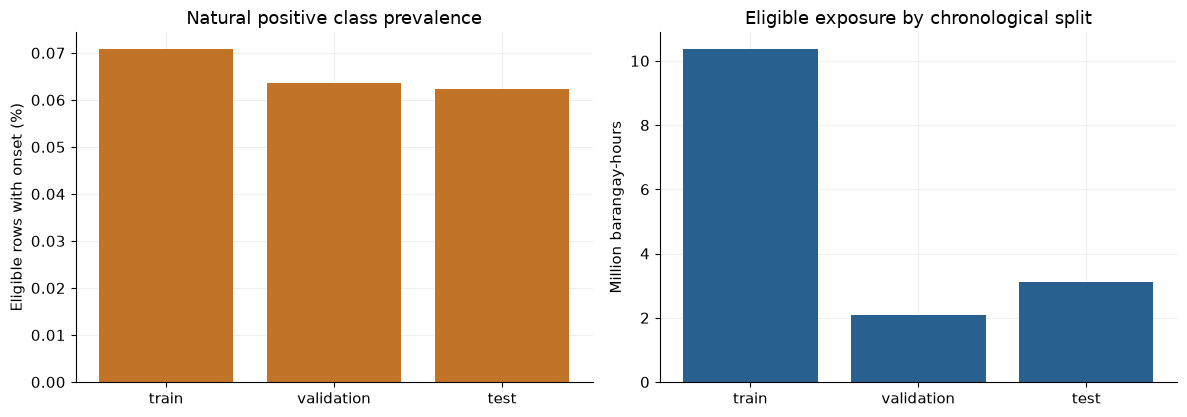

**Observed:** an always-negative rule would obtain **99.93185% accuracy** and zero recall. **Decision:** preserve all 15,538,553 eligible negatives and freeze the chronological split. No ML model is trained or tuned.

,split,cutoff_start_inclusive,cutoff_end_exclusive,cutoff_end_inclusive
0,train,2019-01-01 08:00:00+08:00,2024-01-01 00:00:00+08:00,NaN
1,validation,2024-01-01 00:00:00+08:00,2025-01-01 00:00:00+08:00,NaN
2,test,2025-01-01 00:00:00+08:00,NaN,2026-06-30 23:00:00+08:00


In [23]:
by_split=balance.loc[balance.year.eq('ALL')].copy()
display(by_split[['split','eligible_rows','positives','negatives','excluded_rows','positive_pct','incomplete_feature_rows']].round(5))
display(balance.loc[balance.year.ne('ALL'),['year','split','eligible_rows','positives','negatives','excluded_rows','positive_pct']].round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4.3))
ordered=by_split.set_index('split').reindex(['train','validation','test'])
axes[0].bar(ordered.index,ordered.positive_pct,color=ORANGE)
axes[0].set(title='Natural positive class prevalence',ylabel='Eligible rows with onset (%)')
axes[1].bar(ordered.index,ordered.eligible_rows/1e6,color=BLUE)
axes[1].set(title='Eligible exposure by chronological split',ylabel='Million barangay-hours')
finish('12_class_balance')
always_negative=100*(meta['negative_rows']/meta['eligible_rows'])
display(Markdown(f'**Observed:** an always-negative rule would obtain **{always_negative:.5f}% accuracy** and zero recall. **Decision:** preserve all {meta["negative_rows"]:,} eligible negatives and freeze the chronological split. No ML model is trained or tuned.'))
display(pd.DataFrame([{'split':k,**splits[k]} for k in ['train','validation','test']]))

## 16. Conclusions, limitations and next steps

The builder, teaching examples and production definitions share one implementation; independent NumPy/timestamp-search validation provides a separate check on every retained value and target. Feature selection uses training-period diagnostics only. The matrix is an initial interpretable research subset; no predictive usefulness or forecasting performance has been established.

**Do not equate valid time with availability time.** Open-Meteo historical files are retrospective and lack source model/run/publication metadata. ERA5T typically arrives about five days later; final ERA5 is revised later. One-hour lagging prevents future-valid-time lookahead, but it does not make those values deployable. Reconstruct compatible predictors from archived forecasts with verified issue/publication times before an operational backtest. Annual NDVI, especially the 2026 composite extending through September 23, cannot be used as contemporaneous January–June vegetation information.

Current field semantics were checked against [Open-Meteo's official hourly documentation](https://open-meteo.com/en/docs/historical-weather-api) and [ECMWF's ERA5 documentation](https://confluence.ecmwf.int/spaces/CKB/pages/76414402/ERA5+data+documentation) on 2026-10-26. The CSV's original extraction model/version remains unrecorded, so provider gust semantics are not promoted into a measured subhour peak. Local NetCDF units and GRIB step types were inspected directly.

### Reproduce and validate

From the repository root, using the existing uv environment:

```powershell
uv --cache-dir .venv/uv-cache run --offline python scripts/build_ml_dataset_v2.py --output data/ml/v2_reproduced
uv --cache-dir .venv/uv-cache run --offline python scripts/validate_ml_dataset_v2.py --output data/ml/v2_reproduced
uv --cache-dir .venv/uv-cache run --offline python -m unittest discover -s scripts/tests -p test_ml_v2.py -v
uv --cache-dir .venv/uv-cache run --offline python notebooks/support/execute_eda_feature_engineering_v2.py
```

Existing outputs are never overwritten by the builder. `--help` exposes the source/event/legacy panel and split paths. Notebook execution reads `data/ml/v2` by default and renders small audited artifacts. When source files move, the notebook resolves a unique same-named local file and verifies the event checksum. If uv's launcher is locked, the same installed interpreter is `.venv/Scripts/python.exe`; no package installation is needed.

### Glossary

| Term | Meaning here |
|---|---|
| Prediction cutoff | Time at which the model would receive its inputs |
| Horizon | One hour after the cutoff |
| Leakage | Using information from the future or from the event outcome to predict that event |
| Rolling window | A summary over a fixed number of complete preceding hourly observations |
| Warm-up | Leading period before enough past observations exist |
| Exposure denominator | Number of eligible barangay-hours in which an onset could be counted |
| Reanalysis | Retrospective reconstruction of atmospheric/weather conditions, revised after valid time |
| PSGC | Administrative code used as a string join/grouping identifier |
| Purge | Exclusion of cutoffs whose outcome window touches a later chronological split |

**Next steps require a separate modeling study:** source availability/forecast-vintage audit, training-only preprocessing, simple baselines, validation ablations and calibration, then one frozen test evaluation. Do not infer actual PENELCO forecasting accuracy from synthetic performance.

In [24]:
display(Markdown('\n'.join('- '+text for text in meta['limitations'])))
display(Markdown(f"""**Final decisions:** {meta['engineered_created']} engineered candidates created,
{meta['engineered_retained']} retained; {len(predictors)} total predictors. Exact-year/split class counts,
source hashes, feature definitions, exclusion rules and full independent validation are saved beside the dataset.
The builder verified **{meta['source_preservation']['existing_files_hashed']}** existing files unchanged.
Synthetic V2, topology and application files were not modified. No ML model was trained."""))
assert validation['status']=='passed'
assert set(predictors)==set(manifest.loc[manifest.retained,'feature_name'])
assert meta['positive_rows']+meta['negative_rows']+meta['excluded_rows']==meta['rows']
print('Notebook integrity checks passed; all reported results come from saved, validated outputs.')

- Outage labels are synthetic; municipality allocation is only partially calibrated to resolvable PENELCO records.
- Barangay assignments are probabilistic simulation outputs, not verified PENELCO history.
- Generator environmental relationships are heuristic; learning them does not establish real failure mechanisms or PENELCO forecasting accuracy.
- Historical Open-Meteo and ERA5 inputs are retrospective reconstructions. Valid-time causality is enforced; actual release-time availability is NOT established by a one-hour lag.
- ERA5T commonly arrives about five days later and final ERA5 is revised later; these exact values cannot be assumed available one hour ahead.
- Archived forecast vintages and verified issue/publication times are required before operational forecasting. CAPE, wind, precipitation, temperature and humidity may be reconstructible from forecasts; modeled soil moisture requires a compatible source.
- Same-year NDVI uses future imagery, including September 2026 imagery after June labels. Even prior-year publication dates are absent: NDVI and wind_gust_x_ndvi are deferred.
- Static present-day terrain is applied retrospectively. Municipal weather and coarse ERA5 cells are shared exposures, not independent stations per barangay.
- The generator rejects overlapping local events and durations beyond the right boundary; active masking and boundary truncation change the at-risk population.
- Missing warm-up features remain null. No imputer/scaler is fitted; any later estimator needing complete values must fit its preprocessing on training only.
- Feature selection uses training-only unsupervised diagnostics, not model performance. Correlation does not demonstrate usefulness; ablation and forecasting compatibility remain future work.

**Final decisions:** 17 engineered candidates created,
16 retained; 24 total predictors. Exact-year/split class counts,
source hashes, feature definitions, exclusion rules and full independent validation are saved beside the dataset.
The builder verified **305** existing files unchanged.
Synthetic V2, topology and application files were not modified. No ML model was trained.

Notebook integrity checks passed; all reported results come from saved, validated outputs.
